# 5-09 뉴스정보 가져오기 — 키워드·섹션·언론사·시간대·종목으로 뉴스 모으기

**질문 예시:** "이번 주 경제지 기사 중 HBM 기사 다 모아줘", "오늘 오전 9~12시 삼성전자 기사 뽑아줘",
"SK하이닉스 관련 기사 1년치 CSV로 줘"

`DocumentSearch(["news"], 섹션, 쿼리, count, page, date_from, date_to)` 하나로 다 됩니다. 이 노트북은
자주 쓰는 조건(섹션·언론사 묶음·시간 범위·종목)을 함수 하나로 묶고, 한 페이지 100건 제한과
**검색 기간 1년 제한**을 알아서 넘깁니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/5_data_lookup/09_news.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
import re
ASOF = "2026-11-24"

SECTIONS = {"전체": [], "경제": ["economy"], "기술/IT": ["tech"], "문화": ["culture"], "사설": ["opinion"],
            "사회": ["society"], "세계": ["world"], "연예": ["entertainment"], "정치": ["politics"]}
_P = {
    "중앙일간지": ["경향신문", "국민일보", "동아일보", "서울신문", "세계일보", "아시아투데이", "조선일보", "중앙일보", "한겨레", "한국일보"],
    "중앙경제지": ["뉴스토마토", "디지털타임스", "매일경제", "머니투데이", "서울경제", "아주경제", "이데일리", "이투데이",
               "전자신문", "파이낸셜뉴스", "한국경제"],
    "석간지": ["내일신문", "문화일보", "아시아경제", "지역내일신문", "헤럴드경제"],
    "종합일간지·지방지": ["메트로경제", "국제신문", "부산일보"],
}
_P["중앙일간지·경제지"] = _P["중앙일간지"] + _P["중앙경제지"]
_P["주요 언론사 전체"] = _P["중앙일간지·경제지"] + _P["석간지"] + ["중소기업뉴스"] + _P["종합일간지·지방지"]
PUBLISHER_GROUPS = _P

## 1. 검색 함수
- `publishers`: 묶음 이름이나 언론사 이름 목록 → `publisher.raw:('매일경제' or …)`
- `time_from`/`time_to`: 시각까지 자르려면 `"2026-11-24T09:00:00"` 형식 → 쿼리에 `created_at:[… to …]`
- `stock`: 6자리 종목코드 → `securities.symbol:005930` (그 종목이 주제인 기사)
- 기간이 1년을 넘으면 1년씩 나눠 받고 URL로 중복을 지웁니다.

In [4]:
def doc_pages(category, section, query, date_from, date_to, pages=1, count=100):
    """doc_search 와 같은 표를 주되, 페이지가 count보다 적게 와도 전체 건수에 닿을 때까지 다음 페이지를 받습니다.
    (서버가 중복을 빼고 주는지 한 페이지가 80~90건으로 오는 일이 흔합니다.)"""
    raw, total = [], 0
    for p in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},{json.dumps(query, ensure_ascii=False)},'
             f'count={count},page={p},date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        raw += docs
        if not docs or p * count >= total:
            break
    rows = [{"created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
             "publisher": x.get("publisher"), "title": " ".join(str(x.get("title") or "").split()),
             "stocks": ", ".join(s.get("name", "") for s in x.get("securities") or []),
             "symbols": ", ".join(s.get("symbol", "") for s in x.get("securities") or []),
             "polarity": _polarity(x), "url": x.get("content_url")} for x in raw]
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols).drop_duplicates("url")

def news_search(keyword="", section="전체", publishers=None, date_from=None, date_to=ASOF,
                time_from=None, time_to=None, stock=None, max_pages=3, verbose=True):
    parts = [f"({keyword})"] if keyword else []
    if stock:
        parts.append(f"securities.symbol:{stock}")
    if publishers:
        names = PUBLISHER_GROUPS.get(publishers, publishers) if isinstance(publishers, str) else publishers
        parts.append("publisher.raw:(" + " or ".join(f"'{n}'" for n in names) + ")")
    if time_from and time_to:
        parts.append(f'created_at:["{time_from}" to "{time_to}"]')
    query = " and ".join(parts) or "*"
    date_from = date_from or str(pd.Timestamp(date_to).date() - timedelta(days=6))
    # 1년 한도 → 구간 나누기
    windows, s, e = [], pd.Timestamp(date_from), pd.Timestamp(date_to)
    while s <= e:
        stop = min(s + pd.DateOffset(years=1) - pd.Timedelta(days=1), e)
        windows.append((s.date(), stop.date())); s = stop + pd.Timedelta(days=1)
    frames, total = [], 0
    for a, b in windows:
        t, df = doc_pages("news", SECTIONS[section], query, a, b, pages=max_pages)
        total += t
        frames.append(df)
        if verbose:
            print(f"  {a}~{b}: 전체 {t:,}건 중 {len(df)}건 받음")
    out = pd.concat(frames, ignore_index=True).drop_duplicates("url").sort_values("created_at", ascending=False)
    if verbose:
        print(f"쿼리: {query[:150]}{'…' if len(query) > 150 else ''}\n합계 {total:,}건 중 {len(out)}건")
    return out.reset_index(drop=True)

## 2. 예시 ① 경제 섹션 × 중앙경제지 × 'HBM' (최근 1주)

In [5]:
hbm = news_search("HBM", section="경제", publishers="중앙경제지", max_pages=2)
print(hbm.publisher.value_counts().head(6).to_dict())
hbm[["created_at", "publisher", "title", "stocks", "polarity"]].head(8)

  2026-11-18~2026-11-24: 전체 169건 중 169건 받음
쿼리: (HBM) and publisher.raw:('뉴스토마토' or '디지털타임스' or '매일경제' or '머니투데이' or '서울경제' or '아주경제' or '이데일리' or '이투데이' or '전자신문' or '파이낸셜뉴스' or '한국경제')
합계 169건 중 169건
{'서울경제': 37, '이데일리': 34, '한국경제': 25, '파이낸셜뉴스': 21, '머니투데이': 21, '매일경제': 20}


,created_at,publisher,title,stocks,polarity
0,2026-11-24 22:01:00,한국경제,"""400만닉스는 커녕 100만닉스도 위태""…폭락 맞춘 BNK의 경고 [종목+]",SK하이닉스,부정
1,2026-11-24 19:00:00,이데일리,급한 불 껐지만…지배구조·당국 조사·수익성 검증 과제 산적,,부정
2,2026-11-24 18:27:00,파이낸셜뉴스,"삼성전자, 승진 문턱 높았다… HBM4 주역엔 확실한 보상",삼성전자,중립
3,2026-11-24 18:20:00,한국경제,"삼성, '역대급 호황' 반도체서만 임원 70명 발탁",,중립
4,2026-11-24 18:19:00,파이낸셜뉴스,"""반도체·AI 투자심리 살아났지만 수익성 우려 여전""",,중립
5,2026-11-24 18:18:00,파이낸셜뉴스,'AI 동맹' 삼성·SK 한숨 돌렸다 [젠슨 황 복귀],,중립
6,2026-11-24 18:01:00,한국경제,한숨 돌린 K반도체…HBM 공급처 다변화할 듯,,긍정
7,2026-11-24 17:57:00,서울경제,①블루웨이브發 DC 규제…D램 2028년 공급초과로 돌아설 수도 [젠슨 황 전격 복귀],,긍정


## 3. 예시 ② 날짜+시간 범위 — 11월 24일 오전 9~12시 '삼성전자' 기사
`date_from`/`date_to`는 날짜 단위라, 시간대는 쿼리 안의 `created_at` 범위로 자릅니다.

In [6]:
morning = news_search("삼성전자", date_from=ASOF, date_to=ASOF,
                      time_from=f"{ASOF}T09:00:00", time_to=f"{ASOF}T12:00:00", max_pages=3)
print("시간 범위 확인:", morning.created_at.min(), "~", morning.created_at.max())
morning.created_at.dt.floor("30min").value_counts().sort_index()

  2026-11-24~2026-11-24: 전체 298건 중 258건 받음
쿼리: (삼성전자) and created_at:["2026-11-24T09:00:00" to "2026-11-24T12:00:00"]
합계 298건 중 258건
시간 범위 확인: 2026-11-24 09:00:00 ~ 2026-11-24 12:00:00


created_at
2026-11-24 09:00:00    64
2026-11-24 09:30:00    57
2026-11-24 10:00:00    48
2026-11-24 10:30:00    29
2026-11-24 11:00:00    26
2026-11-24 11:30:00    33
2026-11-24 12:00:00     1
Name: count, dtype: int64

## 4. 예시 ③ 종목 지정 — SK하이닉스가 주제인 기사, 1년 넘게 (자동 분할)
13개월을 요청하면 1년 + 1개월 두 번에 나눠 받습니다. 여기서는 구간마다 1페이지만 받아 흐름만 봅니다.

In [7]:
d0 = (pd.Timestamp(ASOF) - pd.DateOffset(months=13)).date()
hynix = news_search(stock="000660", date_from=d0, max_pages=1)
hynix[["created_at", "publisher", "title", "polarity"]].head(5)

  2025-10-24~2026-10-23: 전체 27,522건 중 80건 받음


  2026-10-24~2026-11-24: 전체 2,701건 중 87건 받음
쿼리: securities.symbol:000660
합계 30,223건 중 167건


,created_at,publisher,title,polarity
0,2026-11-24 22:56:00,이데일리,"앤스로픽, 상장 4거래일 만에 공모가 아래로…엔비디아도 5%↓",부정
1,2026-11-24 22:01:00,한국경제,"""400만닉스는 커녕 100만닉스도 위태""…폭락 맞춘 BNK의 경고 [종목+]",부정
2,2026-11-24 22:01:00,더팩트,"'공소취소 논란' 이용철 ""무리한 지휘 안 해""…측근설도 선 그어(종합)",부정
3,2026-11-24 21:48:00,YTN,'대체 불가'의 역설...AI 황제의 '1인 리스크',중립
4,2026-11-24 20:34:00,경기일보,‘닭백숙집 도박’ 의혹에 이용철 “어릴 때부터 육식 못 해” 반박,부정


기사 **건수 추이**만 필요하면 문서를 받지 말고 `DocumentTrends`(기간 2년까지 한 번에)를 쓰세요.

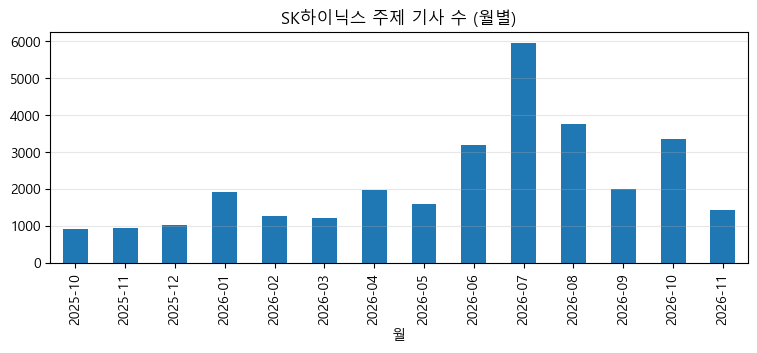

In [8]:
tr = doc_trends("news", [], "securities.symbol:000660", d0, ASOF, interval="1M")
tr["월"] = tr.date.dt.strftime("%Y-%m")
ax = tr.plot.bar(x="월", y="count", figsize=(9, 3), legend=False, title="SK하이닉스 주제 기사 수 (월별)")
ax.grid(alpha=.3, axis="y"); plt.show()

## 5. 기간 중 기사가 많은 언론사
DeepSearch 뉴스 출처는 575곳가량입니다. 어떤 이름으로 들어 있는지는 집계로 확인합니다
(`publisher.raw`는 집계에서 서버 오류가 나고, `publisher`로 하면 됩니다).

In [9]:
c = ds(f'DocumentAggregation(["news"],["economy"],"*","publisher:30",'
       f'date_from={pd.Timestamp(ASOF).date() - timedelta(days=6)},date_to={ASOF})')["data"]["pods"][1]["content"]
pubs = pd.DataFrame(c["data"])[["key", "count"]].rename(columns={"key": "언론사", "count": "경제 기사 수(1주)"})
pubs.head(15)

,언론사,경제 기사 수(1주)
0,연합뉴스,3395
1,뉴시스,2803
2,뉴스1,2353
3,이데일리,1537
4,아시아경제,1504
5,머니투데이,1413
6,파이낸셜뉴스,1288
7,헤럴드경제,1282
8,매일경제,1078
9,한국경제,1049


## 6. DeepSearch 언론사 목록과 빅카인즈 비교
언론사 이름 목록은 레포 `scenarios/_data/`에 있습니다. 로컬에서는 레포 파일을, Colab에서는 GitHub에서 읽습니다.
(2026-01-31 기준: DeepSearch 574곳, 빅카인즈 104곳, 둘 다 45곳)

In [10]:
DATA_URL = "https://raw.githubusercontent.com/beaten-by-the-market/deepsearch/main/scenarios/_data/"

def load_text(name):
    """scenarios/_data/<name> — 로컬 레포에 있으면 그 파일, 없으면 GitHub raw."""
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, "scenarios", "_data", name)
        if os.path.isfile(p):
            return open(p, encoding="utf-8").read()
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    r = requests.get(DATA_URL + name, timeout=30); r.raise_for_status()
    return r.text

ds_pubs = [x.strip() for x in load_text("deepsearch_publishers.txt").splitlines() if x.strip()]
comp = load_text("publisher_comparison.txt")
sections_cmp = {m.group(1): int(m.group(2)) for m in re.finditer(r"--- \[(.+?)\] (\d+)개 ---", comp)}
print(f"DeepSearch 언론사 {len(ds_pubs)}곳 |", sections_cmp)
print("이름 찾기 예 — '경제'가 들어간 곳:", [p for p in ds_pubs if "경제" in p][:12])

DeepSearch 언론사 574곳 | {'둘 다 제공': 45, '빅카인즈만 제공': 59, '딥서치만 제공': 529}
이름 찾기 예 — '경제'가 들어간 곳: ['AI라이프경제', 'ESG경제', '경남경제', '경제투데이', '금융경제', '나이스경제', '내외경제TV', '내외경제플러스', '대전경제뉴스', '동아경제일보', '매일경제', '미래경제']


## 7. CSV로 저장

In [11]:
hbm.to_csv("news_hbm.csv", index=False, encoding="utf-8-sig")
if IN_COLAB:
    from google.colab import files
    files.download("news_hbm.csv")
print("news_hbm.csv 저장:", len(hbm), "건")

news_hbm.csv 저장: 169 건


## 결과 읽는 법과 한계
- **한 번에 100건, 검색 기간 1년**이 API 한도입니다. 위 함수가 페이지와 기간을 나눠 받지만, 수만 건이면 오래 걸립니다.
  건수만 필요하면 `DocumentTrends`·`DocumentAggregation`을 쓰세요.
- `securities.symbol:6자리`는 그 종목이 **주제인** 기사입니다. 본문에 이름만 나온 기사까지 원하면 종목명을 키워드로 넣으세요(수 배 많음).
- 긍부정(`polarity`)은 기사 절반가량에만 원래 값이 있고, 나머지는 DeepSearch 보조 모델 값으로 채웠습니다.